# 02 | Estadística descriptiva

> **Cuaderno de reproducción (posterior).** Generado el 2026-10-23 como parte de la entrega docente. El repositorio original no contenía cuadernos versionados; estos reconstruyen los análisis a partir de los scripts y módulos existentes.

**Tipo de ejecución: CARGA DE DATOS — lee los CSV crudos; NO entrena modelos.**

In [1]:
import os
from pathlib import Path

def _raiz_repositorio() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'data' / 'raw' / 'interseccion_terrenos_zhg_r1_yacopi.csv').exists():
            return p
    raise FileNotFoundError('No se encontro la raiz del repositorio (busca data/raw)')

REPO = _raiz_repositorio()
print('Raiz del repositorio resuelta (carpeta):', REPO.name, '| data/raw encontrado')

Raiz del repositorio resuelta (carpeta): yacopi-project | data/raw encontrado


## Descriptivos y distribuciones

In [2]:
import pandas as pd
inter = pd.read_csv(REPO / 'data/raw/interseccion_terrenos_zhg_r1_yacopi.csv', low_memory=False)
print('destinos:')
print(inter.destino_economico.value_counts().head(6))
print('\nzonas ZHG:', inter.codigo_zona_geoeconomica.nunique())
print('valor zonal COP/ha: min', inter.valor_hectarea_agropecuario.min(),
      'mediana', inter.valor_hectarea_agropecuario.median(),
      'max', inter.valor_hectarea_agropecuario.max())

destinos:
destino_economico
Agropecuario     8354
Religioso         734
Habitacional      241
Institucional      94
Comercial          10
Educativo           8
Name: count, dtype: int64

zonas ZHG: 11
valor zonal COP/ha: min 91206.6 mediana 456041.7 max 3192276.7


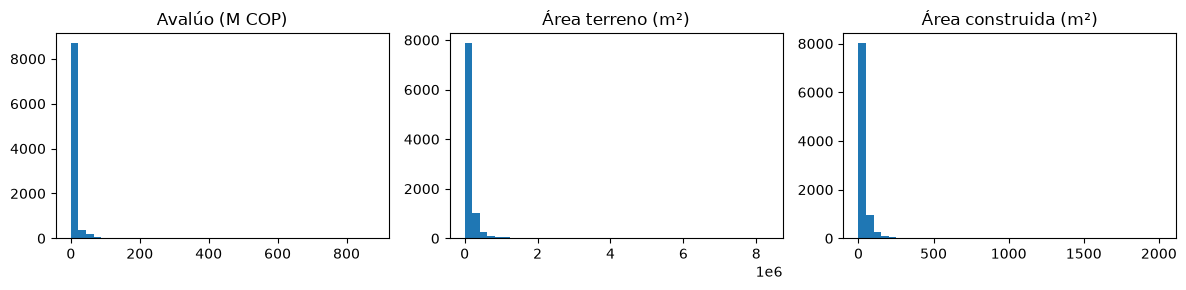

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
axs[0].hist(inter.valor_avaluo / 1e6, bins=40); axs[0].set_title('Avalúo (M COP)')
axs[1].hist(inter.area_terreno_m2, bins=40); axs[1].set_title('Área terreno (m²)')
axs[2].hist(inter.area_construida_m2, bins=40); axs[2].set_title('Área construida (m²)')
plt.tight_layout(); plt.show()